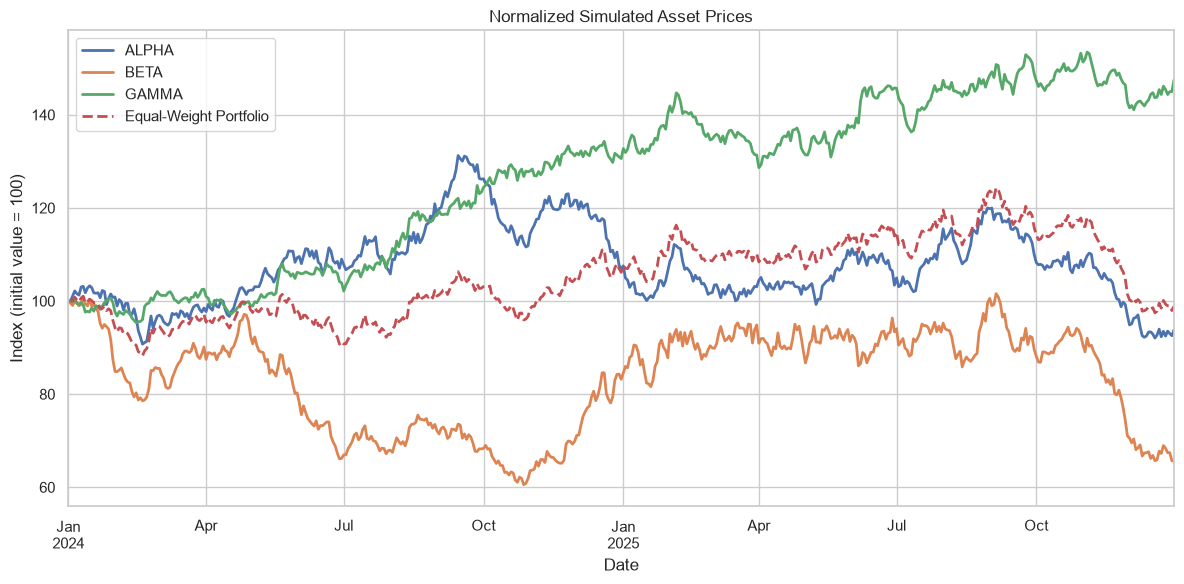

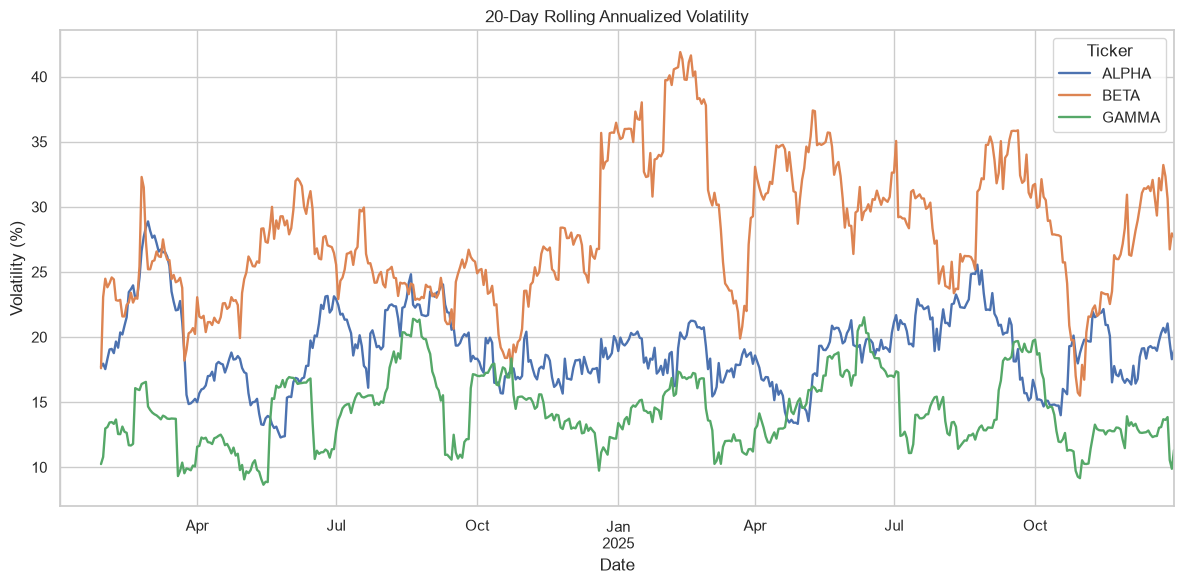

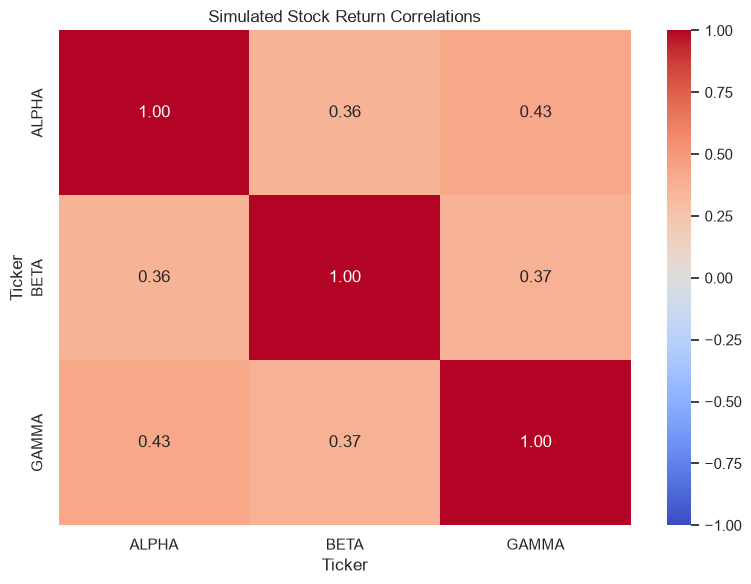

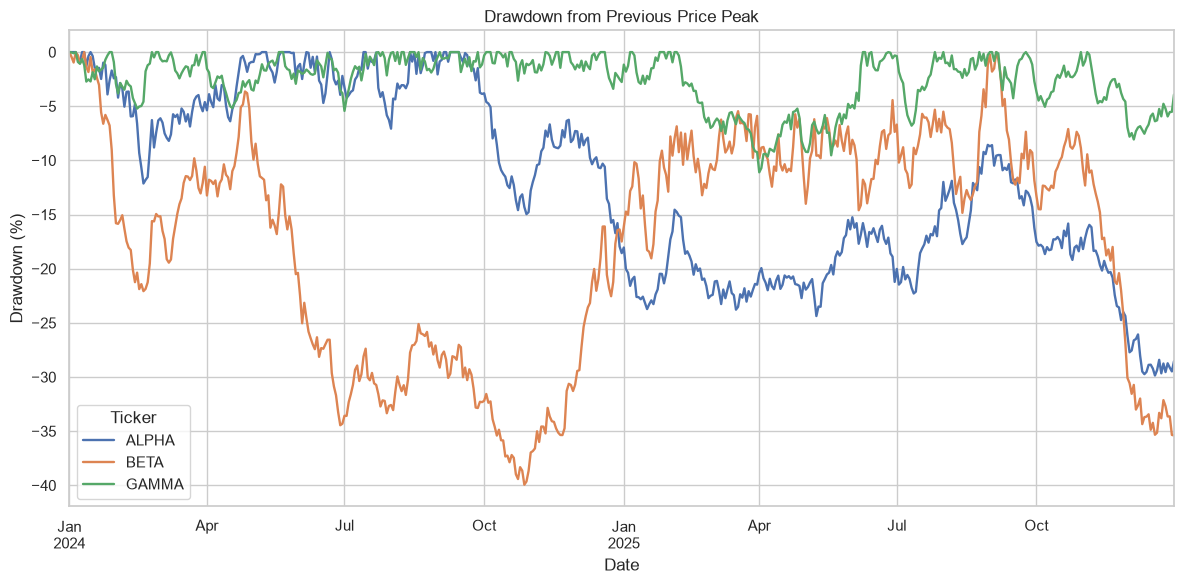

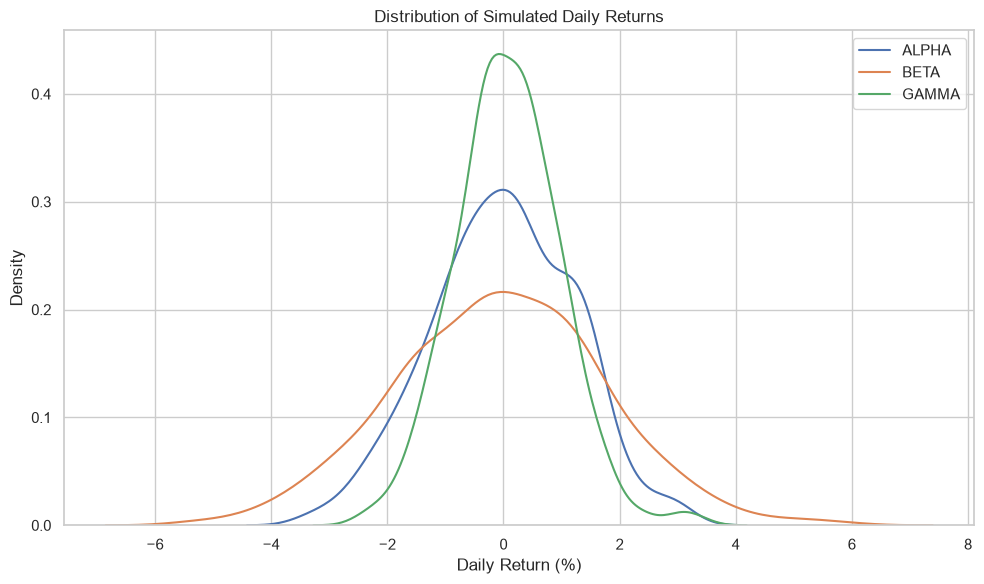


PROJECT 5 COMPLETED
Trading Days: 523
Tickers: ['ALPHA', 'BETA', 'GAMMA']
Highest Return: GAMMA
Highest Volatility: BETA
Portfolio Volatility: 16.09
Hypothesis Test p-value: 0.9283384071359881
Charts: 5
PDF: /Users/ansifrasak/Downloads/Main Projects /The_project_Developers_ARENA/financial-market-analysis/project5_financial_analysis/reports/financial_market_report.pdf
Saved in: /Users/ansifrasak/Downloads/Main Projects /The_project_Developers_ARENA/financial-market-analysis/project5_financial_analysis


In [1]:

# ============================================================
# PROJECT 5: FINANCIAL MARKET ANALYSIS
# ONE-CELL COMPLETE PROJECT
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image, PageBreak
)
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet
from xml.sax.saxutils import escape

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(45)

# 1. PROJECT SETUP
base = Path.cwd()
if base.name == "notebooks":
    base = base.parent
if base.name.startswith("project"):
    base = base.parent
if (base / "Data_Analysis_Portfolio").is_dir():
    base = base / "Data_Analysis_Portfolio"

project_name = "project5_financial_analysis"
root = base / project_name

for name in ["data", "notebooks", "reports",
             "visualizations", "docs", "src"]:
    (root / name).mkdir(parents=True, exist_ok=True)

plots = []

def save_chart(fig, filename):
    fig.tight_layout()
    path = root / "visualizations" / filename
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plots.append(path)
    plt.show()
    plt.close(fig)

def create_report(title, sections, filename):
    styles = getSampleStyleSheet()
    story = [
        Paragraph(escape(title), styles["Title"]),
        Paragraph("Fictional Stock Market Dataset",
                  styles["Italic"]),
        Spacer(1, 15)
    ]

    for heading, paragraphs in sections.items():
        story.append(Paragraph(
            escape(heading), styles["Heading2"]
        ))
        for content in paragraphs:
            story.append(Paragraph(
                escape(str(content)), styles["BodyText"]
            ))
            story.append(Spacer(1, 8))

    for chart in plots:
        story.append(PageBreak())
        story.append(Paragraph(
            escape(chart.stem.replace("_", " ").title()),
            styles["Heading2"]
        ))
        img = Image(str(chart))
        scale = min(
            440 / img.drawWidth,
            620 / img.drawHeight
        )
        img.drawWidth *= scale
        img.drawHeight *= scale
        story.append(img)

    pdf = root / "reports" / filename
    SimpleDocTemplate(
        str(pdf), pagesize=A4, title=title
    ).build(story)
    return pdf

# 2. GENERATE SIMULATED MARKET DATA
dates = pd.bdate_range(
    "2024-01-01", "2025-12-31"
)

n = len(dates)

# Shared market shocks introduce realistic correlation
market_shock = rng.normal(
    0.0002, 0.009, n
)

stocks = {
    "ALPHA": (100, 0.8, 0.009),
    "BETA": (145, 1.2, 0.014),
    "GAMMA": (75, 0.6, 0.007)
}

frames = []

for ticker, (initial, beta, risk) in stocks.items():

    log_returns = (
        0.00015
        + beta * market_shock
        + rng.normal(0, risk, n)
    )

    close_prices = initial * np.exp(
        np.cumsum(log_returns)
    )

    volumes = rng.integers(
        10000, 300000, n
    )

    frames.append(pd.DataFrame({
        "Date": dates,
        "Ticker": ticker,
        "Close": close_prices.round(2),
        "Volume": volumes
    }))

df_raw = pd.concat(
    frames, ignore_index=True
)

# Insert data-quality problems
df_raw.loc[0, "Close"] = 0
df_raw.loc[1, "Volume"] = -100
df_raw.loc[2, "Close"] = np.nan

df_raw = pd.concat(
    [df_raw, df_raw.iloc[[3]]],
    ignore_index=True
)

df_raw.to_csv(
    root / "data" / "market_raw.csv",
    index=False
)

# 3. CLEANING AND VALIDATION
duplicates = df_raw.duplicated(
    subset=["Date", "Ticker"]
).sum()

df = (
    df_raw.drop_duplicates(["Date", "Ticker"])
    .sort_values(["Ticker", "Date"])
    .copy()
)

df["Date"] = pd.to_datetime(df["Date"])

df["Close"] = pd.to_numeric(
    df["Close"], errors="coerce"
)

df["Volume"] = pd.to_numeric(
    df["Volume"], errors="coerce"
)

df.loc[df["Close"] <= 0, "Close"] = np.nan
df.loc[df["Volume"] < 0, "Volume"] = np.nan

# Interpolation used only for this synthetic exercise
df["Close"] = df.groupby("Ticker")[
    "Close"
].transform(
    lambda x: x.interpolate(
        limit_direction="both"
    )
)

df["Volume"] = df.groupby("Ticker")[
    "Volume"
].transform(
    lambda x: x.fillna(x.median())
)

assert df[["Ticker", "Date"]].duplicated().sum() == 0
assert df["Close"].gt(0).all()
assert df["Volume"].ge(0).all()
assert df[["Close", "Volume"]].notna().all().all()

df.to_csv(
    root / "data" / "market_cleaned.csv",
    index=False
)

# 4. PREPARE TIME-SERIES ANALYSIS
prices = df.pivot(
    index="Date",
    columns="Ticker",
    values="Close"
).sort_index()

daily_returns = prices.pct_change(
    fill_method=None
).dropna()

# Normalize to a starting value of 100
normalized_prices = prices.div(
    prices.iloc[0]
) * 100

# Annualized volatility, assuming 252 trading days
annualized_volatility = (
    daily_returns.std() * np.sqrt(252)
) * 100

# Total percentage return for each simulated asset
total_returns = (
    prices.iloc[-1] / prices.iloc[0] - 1
) * 100

# Drawdown from previous running peak
drawdowns = (
    prices.div(prices.cummax()) - 1
) * 100

maximum_drawdowns = drawdowns.min()

# Rolling annualized volatility
rolling_volatility = (
    daily_returns.rolling(20).std()
    * np.sqrt(252)
) * 100

# Correlation matrix
correlation_matrix = daily_returns.corr()

# Illustrative equal-weight daily-rebalanced portfolio
portfolio_returns = daily_returns.mean(axis=1)

portfolio_index = (
    (1 + portfolio_returns).cumprod() * 100
)

portfolio_volatility = (
    portfolio_returns.std() * np.sqrt(252)
) * 100

# 5. STATISTICAL SUMMARY
stock_summary = pd.DataFrame({
    "TotalReturnPct": total_returns,
    "AnnualVolatilityPct": annualized_volatility,
    "MaximumDrawdownPct": maximum_drawdowns,
    "MeanDailyReturnPct": daily_returns.mean() * 100,
    "MedianDailyReturnPct": daily_returns.median() * 100,
    "StdDailyReturnPct": daily_returns.std() * 100
})

# Test whether simulated ALPHA daily mean return differs from zero
t_stat, p_value = stats.ttest_1samp(
    daily_returns["ALPHA"],
    popmean=0
)

stock_summary.to_csv(
    root / "reports" / "stock_statistics.csv"
)

correlation_matrix.to_csv(
    root / "reports" / "return_correlations.csv"
)

daily_returns.to_csv(
    root / "reports" / "daily_returns.csv"
)

portfolio_index.to_csv(
    root / "reports" / "portfolio_index.csv",
    header=["IndexValue"]
)

# 6. CHART 1: NORMALIZED PRICES
fig, ax = plt.subplots(figsize=(12, 6))

normalized_prices.plot(
    ax=ax, linewidth=2
)

portfolio_index.plot(
    ax=ax,
    linewidth=2,
    linestyle="--",
    label="Equal-Weight Portfolio"
)

ax.set_title("Normalized Simulated Asset Prices")
ax.set_xlabel("Date")
ax.set_ylabel("Index (initial value = 100)")
ax.legend()
save_chart(fig, "01_normalized_prices.png")

# 7. CHART 2: ROLLING VOLATILITY
fig, ax = plt.subplots(figsize=(12, 6))

rolling_volatility.plot(
    ax=ax, linewidth=1.7
)

ax.set_title("20-Day Rolling Annualized Volatility")
ax.set_xlabel("Date")
ax.set_ylabel("Volatility (%)")
save_chart(fig, "02_rolling_volatility.png")

# 8. CHART 3: RETURN CORRELATION HEATMAP
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    ax=ax
)

ax.set_title("Simulated Stock Return Correlations")
save_chart(fig, "03_correlation_heatmap.png")

# 9. CHART 4: DRAWDOWN ANALYSIS
fig, ax = plt.subplots(figsize=(12, 6))

drawdowns.plot(
    ax=ax, linewidth=1.7
)

ax.set_title("Drawdown from Previous Price Peak")
ax.set_xlabel("Date")
ax.set_ylabel("Drawdown (%)")
save_chart(fig, "04_drawdown_analysis.png")

# 10. CHART 5: DAILY RETURN DISTRIBUTION
fig, ax = plt.subplots(figsize=(10, 6))

for ticker in daily_returns.columns:
    sns.kdeplot(
        daily_returns[ticker] * 100,
        label=ticker,
        ax=ax
    )

ax.set_title("Distribution of Simulated Daily Returns")
ax.set_xlabel("Daily Return (%)")
ax.legend()
save_chart(fig, "05_return_distribution.png")

# 11. INTERPRET RESULTS
highest_return = total_returns.idxmax()
highest_volatility = annualized_volatility.idxmax()
lowest_volatility = annualized_volatility.idxmin()

findings = [
    f"Simulated trading dates: {len(prices):,}.",
    f"Number of fictional stocks: {len(stocks)}.",
    f"Highest historical simulated return: "
    f"{highest_return}, {total_returns.max():.2f}%.",
    f"Highest annualized volatility: "
    f"{highest_volatility}, "
    f"{annualized_volatility.max():.2f}%.",
    f"Lowest annualized volatility: "
    f"{lowest_volatility}, "
    f"{annualized_volatility.min():.2f}%.",
    f"Equal-weight portfolio annualized volatility: "
    f"{portfolio_volatility:.2f}%.",
    f"ALPHA daily mean return t-test p-value: "
    f"{p_value:.5g}."
]

recommendations = [
    "Report returns together with volatility and "
    "drawdown rather than returns alone.",
    "Use a return-correlation matrix to describe "
    "co-movement among simulated assets.",
    "Compare different analytical risk measures "
    "rather than relying on a single metric.",
    "Recalculate results using verified historical "
    "market data before drawing real-world conclusions.",
    "Avoid using simulated historical performance "
    "as evidence of future returns."
]

sections = {
    "Executive Summary": [
        "This project examines fictional stock price "
        "series for ALPHA, BETA and GAMMA over "
        "2024 and 2025."
    ],
    "Methodology": [
        "Generated correlated simulated prices, "
        "validated observations, calculated daily "
        "returns, annualized volatility, drawdowns, "
        "correlations and a hypothetical equal-weight "
        "daily-rebalanced portfolio."
    ],
    "Data Quality": [
        f"Removed {duplicates} duplicated ticker-date rows.",
        "Nonpositive or missing synthetic prices "
        "were interpolated for this exercise."
    ],
    "Statistical Findings": findings,
    "Analytical Recommendations": recommendations,
    "Limitations": [
        "All tickers and prices are fictional.",
        "No fees, taxes or transaction costs are included.",
        "The portfolio is a hypothetical calculation.",
        "Results provide no basis for buying or selling "
        "real securities.",
        "Return distributions and correlations may "
        "change in actual financial markets."
    ]
}

pdf = create_report(
    "Financial Market Analysis",
    sections,
    "financial_market_report.pdf"
)

# 12. PROJECT DOCUMENTATION
readme = f"""# Financial Market Analysis

## Project
Simulated financial time-series analysis.

## Dataset
- Fictional stocks: ALPHA, BETA, GAMMA
- Period: 2024-2025
- Trading dates: {len(prices)}

## Methods
Returns, volatility, correlation, rolling windows,
drawdown, hypothesis testing and portfolio indexing.

## Results
- Highest simulated return: {highest_return}
- Highest simulated volatility: {highest_volatility}
- Equal-weight volatility: {portfolio_volatility:.2f}%

## Reproduce
Install requirements and run the notebook's single cell.

## Outputs
- data/market_raw.csv
- data/market_cleaned.csv
- reports/financial_market_report.pdf
- reports/stock_statistics.csv
- reports/return_correlations.csv
- reports/daily_returns.csv
- reports/portfolio_index.csv
- visualizations/ (five PNG charts)

## Limitations
Fictional stocks. Educational analytics only.
Not financial or investment advice.
"""

(root / "README.md").write_text(
    readme, encoding="utf-8"
)

(root / "requirements.txt").write_text(
    "pandas\nnumpy\nmatplotlib\nseaborn\nscipy\nreportlab\n",
    encoding="utf-8"
)

(root / "docs" / "methodology.md").write_text(
    "Fictional correlated market data. Annualized "
    "volatility assumes 252 trading days. "
    "The equal-weight portfolio is rebalanced daily. "
    "No real investment decisions should be made "
    "from these results.\n",
    encoding="utf-8"
)

print("\n" + "="*60)
print("PROJECT 5 COMPLETED")
print("="*60)
print("Trading Days:", len(prices))
print("Tickers:", list(prices.columns))
print("Highest Return:", highest_return)
print("Highest Volatility:", highest_volatility)
print("Portfolio Volatility:", round(portfolio_volatility, 2))
print("Hypothesis Test p-value:", p_value)
print("Charts:", len(plots))
print("PDF:", pdf)
print("Saved in:", root)
